# Modelos lineales generalizados y regresión logística

El modelo lineal supone una respuesta continua con errores normales. Muchas respuestas en geociencias no son así: la presencia o ausencia de un deslizamiento es binaria, el número de sismos en un mes es un conteo, la proporción de laderas falladas en una cuenca está entre 0 y 1. Los modelos lineales generalizados (GLM) extienden la regresión lineal a estas respuestas {cite}`mccullagh1989,gelman2007`.

## Estructura de un GLM

Un GLM tiene tres componentes. El componente aleatorio es la distribución de probabilidad de la respuesta, de la familia exponencial: normal, binomial, de Poisson, gamma. El componente sistemático es el predictor lineal, $\eta = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p$. Y la función de enlace $g$ conecta el valor esperado de la respuesta con el predictor lineal, $g(E[y]) = \eta$. El modelo lineal general es el caso particular con distribución normal y enlace identidad. Un GLM no supone una relación lineal entre la respuesta y los predictores, sino entre la respuesta transformada por el enlace y los predictores; no exige normalidad ni homogeneidad de varianza, pero sí independencia de las observaciones. Los coeficientes se estiman por máxima verosimilitud.

## Regresión logística

Para una respuesta binaria se usa la distribución de Bernoulli con el enlace logit, el logaritmo de los odds:

$$\log\frac{p}{1-p} = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p, \qquad p = \frac{1}{1 + e^{-\eta}}.$$

Los odds (momios) son la razón entre la probabilidad de que ocurra el evento y la de que no ocurra. Cada coeficiente es el cambio en el logaritmo de los odds por un aumento de una unidad del predictor, y su exponencial, $e^{\beta_j}$, es la razón de odds: el factor por el que se multiplican los odds. Un $e^{\beta}$ de 1.5 indica que los odds aumentan un 50 %; uno de 0.7, que disminuyen un 30 %. Los odds son menos intuitivos que las probabilidades, así que suele ser útil graficar las probabilidades predichas (los efectos marginales) para combinaciones de los predictores.

La regresión logística es el modelo de referencia en los estudios de susceptibilidad por deslizamientos {cite}`pourghasemi2019`. La celda siguiente la ajusta a un inventario sintético con una variable categórica, la litología, codificada con variables indicadoras respecto a una categoría de referencia (el granito).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
plt.rcParams['figure.dpi'] = 100
rng = np.random.default_rng(10)

n = 2500
pend = rng.gamma(4, 6, n); dist = rng.exponential(250, n)
lito = rng.choice(['granito', 'esquisto', 'lutita'], n, p=[0.4, 0.35, 0.25])
efecto = pd.Series(lito).map({'granito': 0, 'esquisto': 0.7, 'lutita': 1.3}).values
eta = -4.0 + 0.09 * pend - 0.003 * dist + efecto
y = (rng.random(n) < 1 / (1 + np.exp(-eta))).astype(int)
X = np.column_stack([pend, dist, lito == 'esquisto', lito == 'lutita']).astype(float)
nombres = ['pendiente (°)', 'dist. cauce (m)', 'esquisto', 'lutita']

def logistica(X, y, iters=50):
    """Regresión logística por máxima verosimilitud (Newton-Raphson / IRLS), con errores estándar."""
    Xd = np.column_stack([np.ones(len(y)), X]); b = np.zeros(Xd.shape[1])
    for _ in range(iters):
        p = 1 / (1 + np.exp(-Xd @ b)); W = p * (1 - p)
        H = Xd.T @ (Xd * W[:, None])
        b = b + np.linalg.solve(H, Xd.T @ (y - p))
    se = np.sqrt(np.diag(np.linalg.inv(H)))
    loglik = np.sum(y * np.log(p) + (1 - y) * np.log(1 - p))
    return b, se, loglik

b, se, ll = logistica(X, y)
print(f'{"":16s} {"coef":>8s} {"err.est.":>9s} {"z":>7s} {"p":>9s} {"razón de odds":>14s}')
for nm, bi, si in zip(['intercepto'] + nombres, b, se):
    print(f'{nm:16s} {bi:8.4f} {si:9.4f} {bi/si:7.2f} {2*stats.norm.sf(abs(bi/si)):9.2g} {np.exp(bi):14.3f}')
print(f'\nLog-verosimilitud {ll:.1f}   AIC = {2 * len(b) - 2 * ll:.1f}')

                     coef  err.est.       z         p  razón de odds
intercepto        -4.0100    0.1961  -20.45   6.2e-93          0.018
pendiente (°)      0.0964    0.0053   18.15   1.3e-73          1.101
dist. cauce (m)   -0.0030    0.0003   -8.78   1.6e-18          0.997
esquisto           0.4981    0.1479    3.37   0.00076          1.646
lutita             1.3107    0.1464    8.95   3.4e-19          3.709

Log-verosimilitud -930.1   AIC = 1870.3


Los coeficientes recuperan bien los valores con que se simularon los datos. Un grado más de pendiente multiplica los odds de deslizamiento por cerca de 1.09 (un aumento del 9 %); estar sobre lutitas los multiplica por cerca de 3.7 respecto al granito. Para la distancia al cauce, cuya unidad es pequeña, es más útil expresar el efecto por cada 100 m: $e^{100\beta}$.

## Selección y comparación de modelos

Los GLM anidados se comparan con la prueba de razón de verosimilitudes: el doble de la diferencia de log-verosimilitudes sigue aproximadamente una distribución chi-cuadrado con tantos grados de libertad como parámetros de diferencia. El criterio de información de Akaike, $\mathrm{AIC} = 2k - 2\log L$, permite comparar también modelos no anidados y penaliza la complejidad; se prefiere el de menor AIC.

In [2]:
_, _, ll_sin = logistica(X[:, :2], y)
lr = 2 * (ll - ll_sin)
print(f'Modelo sin litología: AIC = {2*3 - 2*ll_sin:.1f}')
print(f'Prueba de razón de verosimilitudes (litología): estadístico {lr:.1f}, p = {stats.chi2.sf(lr, 2):.2g}')

Modelo sin litología: AIC = 1951.3
Prueba de razón de verosimilitudes (litología): estadístico 85.1, p = 3.4e-19


La celda siguiente grafica las probabilidades predichas en función de la pendiente para cada litología, a una distancia al cauce fija, y el mapa de susceptibilidad resultante sobre un terreno sintético.

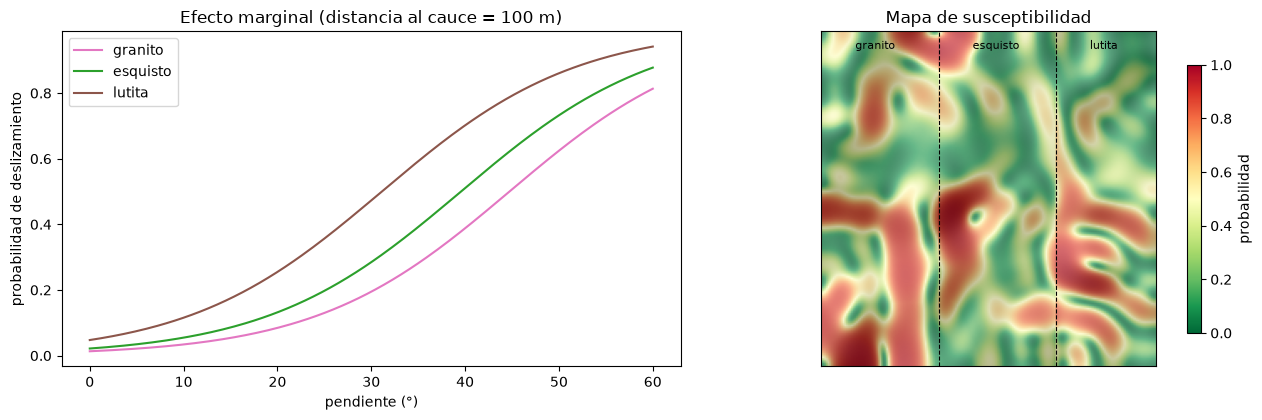

In [3]:
pp = np.linspace(0, 60, 200)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.3))
for lt, col in [('granito', 'tab:pink'), ('esquisto', 'tab:green'), ('lutita', 'tab:brown')]:
    e = b[0] + b[1] * pp + b[2] * 100 + b[3] * (lt == 'esquisto') + b[4] * (lt == 'lutita')
    axs[0].plot(pp, 1 / (1 + np.exp(-e)), color=col, label=lt)
axs[0].set_xlabel('pendiente (°)'); axs[0].set_ylabel('probabilidad de deslizamiento'); axs[0].legend(); axs[0].set_title('Efecto marginal (distancia al cauce = 100 m)')
from matplotlib.colors import LightSource
from scipy import ndimage
g = 200
zz = ndimage.gaussian_filter(rng.normal(0, 1, (g, g)), 12); zz = (zz - zz.min()) / (zz.max() - zz.min()) * 900
gy, gx = np.gradient(zz, 10.0); pend_m = np.degrees(np.arctan(np.hypot(gx, gy)))
cauce = zz < np.quantile(zz, 0.08)
dist_m = ndimage.distance_transform_edt(~cauce) * 10
lito_m = np.where(np.arange(g)[None, :] < 70, 0, np.where(np.arange(g)[None, :] < 140, 1, 2)).repeat(g, 0)
e = b[0] + b[1] * pend_m + b[2] * dist_m + b[3] * (lito_m == 1) + b[4] * (lito_m == 2)
h = axs[1].imshow(1 / (1 + np.exp(-e)), cmap='RdYlGn_r', vmin=0, vmax=1)
axs[1].imshow(LightSource(315, 45).hillshade(zz, dx=10, dy=10), cmap='gray', alpha=0.35)
for xv in [70, 140]: axs[1].axvline(xv, color='k', ls='--', lw=0.8)
axs[1].text(20, 10, 'granito', fontsize=8); axs[1].text(90, 10, 'esquisto', fontsize=8); axs[1].text(160, 10, 'lutita', fontsize=8)
axs[1].set_xticks([]); axs[1].set_yticks([]); axs[1].set_title('Mapa de susceptibilidad'); fig.colorbar(h, ax=axs[1], shrink=0.8, label='probabilidad')
plt.tight_layout(); plt.show()

## Regresión de Poisson para conteos

Para conteos (sismos por mes, deslizamientos por cuenca, réplicas por día) se usa la distribución de Poisson con enlace logarítmico, $\log E[y] = \eta$. Cada $e^{\beta_j}$ es el factor multiplicativo sobre el conteo esperado. Si las unidades tienen distinto tamaño o tiempo de exposición (cuencas de distinta área, por ejemplo), se agrega el logaritmo de la exposición como término fijo (offset), de modo que se modela la tasa. Si la varianza de los conteos es mucho mayor que la media (sobredispersión), la Poisson subestima los errores estándar, y conviene usar la binomial negativa; si hay muchos más ceros de los esperados, los modelos inflados en cero.

In [4]:
from sklearn.linear_model import PoissonRegressor
nc = 300
area = rng.uniform(2, 40, nc)                                   # km²
lluvia_max = rng.uniform(40, 160, nc)                           # mm en 24 h
pend_media = rng.uniform(10, 35, nc)
tasa = np.exp(-6 + 0.025 * lluvia_max + 0.08 * pend_media)      # deslizamientos por km²
conteo = rng.poisson(tasa * area)
Xc = np.column_stack([lluvia_max, pend_media])
pr = PoissonRegressor(alpha=0, max_iter=1000).fit(Xc, conteo / area, sample_weight=area)   # tasa con la exposición como peso
print('Coeficientes estimados (lluvia, pendiente):', np.round(pr.coef_, 4), ' verdaderos: [0.025, 0.08]')
print(f'Media de los conteos {conteo.mean():.2f}, varianza {conteo.var():.2f}')
print(f'Un aumento de 50 mm en la lluvia máxima multiplica la tasa por {np.exp(50 * pr.coef_[0]):.2f}')

Coeficientes estimados (lluvia, pendiente): [0.0241 0.0795]  verdaderos: [0.025, 0.08]
Media de los conteos 6.23, varianza 72.95
Un aumento de 50 mm en la lluvia máxima multiplica la tasa por 3.34


## Más allá: modelos aditivos y multinivel

Los modelos aditivos generalizados (GAM) reemplazan los términos lineales por funciones suaves (splines) estimadas a partir de los datos, $g(E[y]) = \beta_0 + f_1(x_1) + \dots + f_p(x_p)$, y capturan relaciones no lineales conservando la interpretabilidad {cite}`wood2017`. Los modelos multinivel o jerárquicos agregan efectos aleatorios para datos agrupados, como muestras dentro de cuencas o estaciones dentro de regiones, y permiten que el intercepto o las pendientes varíen entre grupos {cite}`gelman2007`. Ambos, en sus versiones frecuentista y bayesiana, se desarrollan en los notebooks 15, 21 y 22 del curso.

## Para profundizar

El capítulo 4 de {cite}`james2021` presenta la regresión logística, y los capítulos 5 y 6 de {cite}`gelman2007`, los GLM con muchos ejemplos de interpretación. {cite:t}`mccullagh1989` es la referencia teórica.